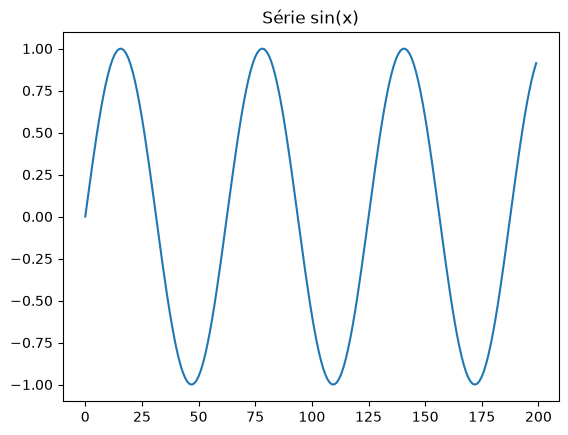

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 200 points de sin(x) entre 0 et 20
serie = torch.sin(torch.linspace(0, 20, 200))

# Fenêtres glissantes : 10 valeurs -> la suivante
X = torch.stack([serie[i:i + 10] for i in range(190)]).unsqueeze(-1)  # (190, 10, 1)
y = torch.stack([serie[i + 10] for i in range(190)]).unsqueeze(-1)    # (190, 1)

# Découpage chronologique : début = entraînement, fin = test
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

plt.plot(serie)
plt.title("Série sin(x)")
plt.show()

In [2]:
class MiniTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(1, 16)       # chaque valeur -> vecteur de 16
        self.positions = nn.Embedding(10, 16)    # un vecteur appris par position (0..9)

        couche = nn.TransformerEncoderLayer(
            d_model=16, nhead=2, dim_feedforward=32,
            dropout=0.0, batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        indices = torch.arange(x.shape[1])                     # [0, 1, ..., 9]
        h = self.projection(x) + self.positions(indices)       # (B, 10, 16)
        h = self.encodeur(h)                                   # (B, 10, 16)
        return self.sortie(h[:, -1, :])                        # dernière position -> (B, 1)

modele = MiniTransformer()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [3]:
for epoch in range(300):
    modele.train()
    perte = critere(modele(X_train), y_train)
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1} | perte : {perte.item():.6f}")

modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    print(f"\nErreur de test (MSE) : {critere(predictions, y_test).item():.6f}")

Epoch 50 | perte : 0.001504
Epoch 100 | perte : 0.000110
Epoch 150 | perte : 0.000026
Epoch 200 | perte : 0.000012
Epoch 250 | perte : 0.000007
Epoch 300 | perte : 0.000004

Erreur de test (MSE) : 0.000006


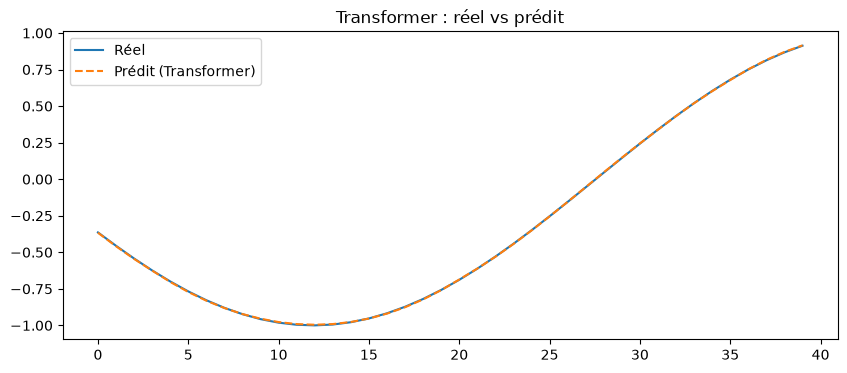

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(y_test.numpy(), label="Réel")
plt.plot(predictions.numpy(), "--", label="Prédit (Transformer)")
plt.title("Transformer : réel vs prédit")
plt.legend()
plt.show()

## Comparatif (erreur de test, MSE)
| Modèle | MSE test |
|---|---|
| RNN | 0.000028 |
| LSTM | 0.000003 |
| Transformer | 0.000006 |

Sur une sinusoïde simple avec 10 valeurs, les trois modèles réussissent.
Le Transformer se distingue surtout sur des séquences longues et complexes,
grâce à l'attention et au calcul en parallèle.